# Dataset Load & Check

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import time
import numpy as np
import pandas as pd

DATA_PATH = "/content/drive/MyDrive/Maharashtra_Agri_Master_2024_Jul2025.csv"

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Shape:", df.shape)
print("Columns:")
print(df.columns.tolist())

Dataset loaded successfully.
Shape: (287933, 35)
Columns:
['State', 'District', 'Market', 'Commodity Group', 'Commodity', 'Date', 'Arrival Quantity', 'Arrival Unit', 'Modal Price', 'Price Unit', 'Latitude', 'Longitude', 'Temperature_C', 'Min_Temperature_C', 'Max_Temperature_C', 'Precipitation_mm', 'Relative_Humidity_Percent', 'pH_0_30', 'Organic_Carbon_g_kg_0_30', 'Nitrogen_g_kg_0_30', 'Clay_percent_0_30', 'CEC_cmolc_kg_0_30', 'Soil_Data_Method', 'Crop_Duration_Days', 'Typical_Sowing_Season', 'Crop_Data_Source', 'Duration_Definition', 'Year', 'Month', 'Day', 'DayOfYear', 'WeekOfYear', 'Quarter', 'Month_Sin', 'Month_Cos']


In [ ]:

#COLUMN AND DATA CHECK

print("ALL COLUMNS")

for i, col in enumerate(df.columns, start=1):
    print(f"{i:02d}. {col}  |  dtype: {df[col].dtype}")

print("\nDATAFRAME INFORMATION")
df.info()

print()
display(df.head())

print("\nMISSING VALUES")
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if missing.empty:
    print("No missing values found.")
else:
    display(missing.to_frame("Missing_Count"))

print("\nDUPLICATE ROWS")
print(df.duplicated().sum())


ALL COLUMNS
01. State  |  dtype: object
02. District  |  dtype: object
03. Market  |  dtype: object
04. Commodity Group  |  dtype: object
05. Commodity  |  dtype: object
06. Date  |  dtype: object
07. Arrival Quantity  |  dtype: float64
08. Arrival Unit  |  dtype: object
09. Modal Price  |  dtype: float64
10. Price Unit  |  dtype: object
11. Latitude  |  dtype: float64
12. Longitude  |  dtype: float64
13. Temperature_C  |  dtype: float64
14. Min_Temperature_C  |  dtype: float64
15. Max_Temperature_C  |  dtype: float64
16. Precipitation_mm  |  dtype: float64
17. Relative_Humidity_Percent  |  dtype: float64
18. pH_0_30  |  dtype: float64
19. Organic_Carbon_g_kg_0_30  |  dtype: float64
20. Nitrogen_g_kg_0_30  |  dtype: float64
21. Clay_percent_0_30  |  dtype: float64
22. CEC_cmolc_kg_0_30  |  dtype: float64
23. Soil_Data_Method  |  dtype: object
24. Crop_Duration_Days  |  dtype: int64
25. Typical_Sowing_Season  |  dtype: object
26. Crop_Data_Source  |  dtype: object
27. Duration_Definitio

,State,District,Market,Commodity Group,Commodity,Date,Arrival Quantity,Arrival Unit,Modal Price,Price Unit,...,Crop_Data_Source,Duration_Definition,Year,Month,Day,DayOfYear,WeekOfYear,Quarter,Month_Sin,Month_Cos
0,Maharashtra,Jalgaon,Bhusaval APMC,Vegetables,Banana - Green,2024-05-07,0.5,Metric Tonnes,2800.0,Rs./Quintal,...,ICAR / agricultural crop production references...,Representative days to first harvest/maturity,2024,5,7,128,19,2,0.5,-0.866025
1,Maharashtra,Jalgaon,Bhusaval APMC,Vegetables,Banana - Green,2024-05-11,0.2,Metric Tonnes,3000.0,Rs./Quintal,...,ICAR / agricultural crop production references...,Representative days to first harvest/maturity,2024,5,11,132,19,2,0.5,-0.866025
2,Maharashtra,Jalgaon,Bhusaval APMC,Vegetables,Banana - Green,2024-05-15,0.5,Metric Tonnes,3000.0,Rs./Quintal,...,ICAR / agricultural crop production references...,Representative days to first harvest/maturity,2024,5,15,136,20,2,0.5,-0.866025
3,Maharashtra,Jalgaon,Bhusaval APMC,Vegetables,Banana - Green,2024-05-17,0.5,Metric Tonnes,2800.0,Rs./Quintal,...,ICAR / agricultural crop production references...,Representative days to first harvest/maturity,2024,5,17,138,20,2,0.5,-0.866025
4,Maharashtra,Jalgaon,Bhusaval APMC,Vegetables,Banana - Green,2024-05-23,0.5,Metric Tonnes,3000.0,Rs./Quintal,...,ICAR / agricultural crop production references...,Representative days to first harvest/maturity,2024,5,23,144,21,2,0.5,-0.866025



MISSING VALUES
No missing values found.

DUPLICATE ROWS
0


In [ ]:

#target and date check

required_columns = [
    "Date",
    "District",
    "Market",
    "Commodity",
    "Modal Price"
]

missing_required = [
    col for col in required_columns
    if col not in df.columns
]

if missing_required:
    raise ValueError(
        f"Required columns are missing: {missing_required}"
    )

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

print("Invalid/missing dates:", df["Date"].isna().sum())
print("Missing target values:", df["Modal Price"].isna().sum())

print("\nDATE RANGE")
print("First date:", df["Date"].min())
print("Last date:", df["Date"].max())

print("\nTARGET SUMMARY")
display(df["Modal Price"].describe())

print("\nTARGET VALIDITY")
print("Infinite target values:",
      np.isinf(df["Modal Price"].dropna()).sum())
print("Zero or negative target values:",
      (df["Modal Price"].dropna() <= 0).sum())

print("\nUNIQUE ENTITIES")
print("Districts:", df["District"].nunique())
print("Markets:", df["Market"].nunique())
print("Commodities:", df["Commodity"].nunique())


Invalid/missing dates: 0
Missing target values: 0

DATE RANGE
First date: 2024-01-01 00:00:00
Last date: 2025-07-31 00:00:00

TARGET SUMMARY


,Modal Price
count,287933.000000
mean,2844.842271
std,2754.652470
min,1.000000
25%,1300.000000
50%,2250.000000
75%,3500.000000
max,120000.000000



TARGET VALIDITY
Infinite target values: 0
Zero or negative target values: 0

UNIQUE ENTITIES
Districts: 24
Markets: 129
Commodities: 38


In [ ]:

# crop market check

series_keys = ["Commodity", "Market"]

# district for each market check
market_district_counts = (
    df.groupby("Market", dropna=False)["District"]
      .nunique(dropna=False)
)

print("Markets associated with multiple district values:",
      (market_district_counts > 1).sum())

# observations for each crop market combination.
series_summary = (
    df.groupby(series_keys, dropna=False)
      .agg(
          observations=("Date", "size"),
          first_date=("Date", "min"),
          last_date=("Date", "max"),
          unique_dates=("Date", "nunique"),
          unique_districts=("District", "nunique")
      )
      .reset_index()
)

print("\nNumber of crop-market series:", len(series_summary))
print("\nOBSERVATION COUNTS PER SERIES")
display(series_summary["observations"].describe(
    percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]
).to_frame("Value"))

print("\nSERIES WITH FEWER THAN 15 ROWS:",
      (series_summary["observations"] < 15).sum())

print("SERIES WITH AT LEAST 15 ROWS:",
      (series_summary["observations"] >= 15).sum())

print("\nSAMPLE SERIES")
display(
    series_summary.sort_values(
        "observations", ascending=False
    ).head(15)
)


Markets associated with multiple district values: 0

Number of crop-market series: 1202

OBSERVATION COUNTS PER SERIES


,Value
count,1202.000000
mean,239.544925
std,169.947012
min,1.000000
10%,6.000000
25%,64.250000
50%,242.500000
75%,409.000000
90%,447.900000
max,546.000000



SERIES WITH FEWER THAN 15 ROWS: 156
SERIES WITH AT LEAST 15 ROWS: 1046

SAMPLE SERIES


,Commodity,Market,observations,first_date,last_date,unique_dates,unique_districts
1188,Tomato,Pune(Pimpri) APMC,546,2024-01-01,2025-07-31,546,1
435,Coriander(Leaves),Pune(Pimpri) APMC,533,2024-01-01,2025-07-31,533,1
67,Bhindi(Ladies Finger),Pune(Manjri) APMC,531,2024-01-01,2025-07-31,531,1
1186,Tomato,Pune(Manjri) APMC,531,2024-01-01,2025-07-31,531,1
1053,Ridgeguard(Tori),Pune(Manjri) APMC,530,2024-01-01,2025-07-31,530,1
347,Cauliflower,Pune(Manjri) APMC,530,2024-01-01,2025-07-31,530,1
261,Cabbage,Pune(Manjri) APMC,529,2024-01-01,2025-07-31,529,1
210,Brinjal,Pune(Manjri) APMC,528,2024-01-01,2025-07-31,528,1
479,Cucumbar(Kheera),Pune(Manjri) APMC,527,2024-01-01,2025-07-31,527,1
1022,Raddish,Pune(Manjri) APMC,526,2024-01-01,2025-07-31,526,1


In [ ]:
previously_dropped = [
    "State",
    "Commodity Group",
    "Latitude",
    "Longitude",
    "Soil_Data_Method",
    "Crop_Data_Source",
    "Duration_Definition"
]

for col in previously_dropped:
    if col not in df.columns:
        print(f"\n{col}: NOT PRESENT")
        continue

    print(f"\n--- {col} ---")
    print("Missing values:", df[col].isna().sum())
    print("Unique values:", df[col].nunique(dropna=False))

    if df[col].nunique(dropna=False) <= 20:
        print(df[col].value_counts(dropna=False).to_dict())
    else:
        print("Sample values:",
              df[col].drop_duplicates().head(10).tolist())



--- State ---
Missing values: 0
Unique values: 1
{'Maharashtra': 287933}

--- Commodity Group ---
Missing values: 0
Unique values: 1
{'Vegetables': 287933}

--- Latitude ---
Missing values: 0
Unique values: 24
Sample values: [21.00292, 19.07283, 21.14631, 18.51957, 19.09457, 20.93333, 19.95076, 18.18158, 16.69563, 19.99727]

--- Longitude ---
Missing values: 0
Unique values: 24
Sample values: [75.56602, 72.88261, 79.08491, 73.85535, 74.73843, 77.75, 79.29523, 76.03889, 74.23167, 73.79096]

--- Soil_Data_Method ---
Missing values: 0
Unique values: 7
{'SoilGrids': 98728, 'Imputed from nearest district: Satara': 79577, 'Imputed from nearest district: Palghar': 40691, 'Imputed from nearest district: Chandrapur': 29533, 'Imputed from nearest district: Dharashiv': 19241, 'Imputed from nearest district: Buldhana': 10570, 'Imputed from nearest district: Jalna': 9593}

--- Crop_Data_Source ---
Missing values: 0
Unique values: 1
{'ICAR / agricultural crop production references; representative v

# Forecasting design and series integrity

In [ ]:

# SERIES INTEGRITY CHECKS

df["Date"] = pd.to_datetime(df["Date"], errors="raise")

series_keys = ["Commodity", "Market"]

# duplicate dates within a crop market series check
duplicate_mask = df.duplicated(
    subset=series_keys + ["Date"],
    keep=False
)

print("Rows involved in duplicate cropmarket date keys:",
      int(duplicate_mask.sum()))

if duplicate_mask.any():
    display(
        df.loc[
            duplicate_mask,
            series_keys + ["District", "Date", "Modal Price"]
        ]
        .sort_values(series_keys + ["Date"])
        .head(30)
    )
else:
    print("Each cropmarket series has at most one row per date.")

market_districts = (
    df.groupby("Market")["District"]
      .nunique()
)

print("\nMarkets mapped to more than one district:",
      int((market_districts > 1).sum()))

# units check
for col in ["Price Unit", "Arrival Unit"]:
    unit_counts = (
        df.groupby(series_keys)[col]
          .nunique(dropna=False)
    )
    print(
        f"Series with multiple {col} values:",
        int((unit_counts > 1).sum())
    )

# split check
train_end_date = pd.Timestamp("2025-04-30")
test_start_date = pd.Timestamp("2025-05-01")
test_end_date = pd.Timestamp("2025-07-31")

print("\nTRAIN ROWS:",
      int((df["Date"] <= train_end_date).sum()))

print("TEST ROWS:",
      int(df["Date"].between(test_start_date, test_end_date).sum()))

print("Rows after expected test end date:",
      int((df["Date"] > test_end_date).sum()))


Rows involved in duplicate cropmarket date keys: 0
Each cropmarket series has at most one row per date.

Markets mapped to more than one district: 0
Series with multiple Price Unit values: 0
Series with multiple Arrival Unit values: 0

TRAIN ROWS: 238090
TEST ROWS: 49843
Rows after expected test end date: 0


In [ ]:

#TRAIN TEST COVERAGE
train_mask = df["Date"] <= train_end_date
test_mask = (
    (df["Date"] >= test_start_date) &
    (df["Date"] <= test_end_date)
)

coverage = (
    df.assign(
        is_train=train_mask,
        is_test=test_mask
    )
    .groupby(series_keys, dropna=False)
    .agg(
        train_observations=("is_train", "sum"),
        test_observations=("is_test", "sum"),
        first_date=("Date", "min"),
        last_date=("Date", "max")
    )
    .reset_index()
)

coverage["has_14_train_observations"] = (
    coverage["train_observations"] >= 14
)

coverage["has_train_and_test"] = (
    (coverage["train_observations"] >= 14) &
    (coverage["test_observations"] > 0)
)

print("Total series:", len(coverage))
print("Series with at least 14 training observations:",
      int(coverage["has_14_train_observations"].sum()))
print("Series with 14+ training observations and test rows:",
      int(coverage["has_train_and_test"].sum()))

print("\nTRAIN OBSERVATION DISTRIBUTION")
display(coverage["train_observations"].describe())

print("\nTEST OBSERVATION DISTRIBUTION")
display(coverage["test_observations"].describe())

print("\nSERIES WITH TEST OBSERVATIONS BUT LESS THAN 14 TRAIN ROWS")
display(
    coverage.loc[
        (coverage["test_observations"] > 0) &
        (coverage["train_observations"] < 14)
    ].head(20)
)

Total series: 1202
Series with at least 14 training observations: 1032
Series with 14+ training observations and test rows: 978

TRAIN OBSERVATION DISTRIBUTION


,train_observations
count,1202.000000
mean,198.078203
std,141.907244
min,0.000000
25%,53.000000
50%,200.000000
75%,338.750000
max,459.000000



TEST OBSERVATION DISTRIBUTION


,test_observations
count,1202.000000
mean,41.466722
std,29.995658
min,0.000000
25%,7.000000
50%,48.000000
75%,70.000000
max,88.000000



SERIES WITH TEST OBSERVATIONS BUT LESS THAN 14 TRAIN ROWS


,Commodity,Market,train_observations,test_observations,first_date,last_date,has_14_train_observations,has_train_and_test
28,Beetroot,SHRI.SIDDHESHWAR APMC,0,2,2025-07-28,2025-07-30,False,False
29,Beetroot,Vadgaonpeth APMC,1,1,2025-03-13,2025-06-11,False,False
39,Bhindi(Ladies Finger),Ghoti APMC,2,1,2025-02-14,2025-06-27,False,False
59,Bhindi(Ladies Finger),Pandharpur APMC,1,1,2025-01-29,2025-05-28,False,False
62,Bhindi(Ladies Finger),Parshiwani APMC,11,8,2024-07-22,2025-07-28,False,False
91,Bitter gourd,Ghoti APMC,11,3,2024-09-28,2025-05-24,False,False
122,Bitter gourd,Rahuri(Songaon) APMC,8,1,2024-05-22,2025-06-03,False,False
163,Bottle gourd,Ratnagiri (Nachane) APMC,13,3,2024-01-22,2025-07-22,False,False
200,Brinjal,Pandharpur APMC,3,14,2024-02-28,2025-07-29,False,False
203,Brinjal,Parshiwani APMC,13,8,2024-07-22,2025-07-28,False,False


# LSTM specific feature engineering

In [ ]:

#TIME FEATURES
df_lstm = df.copy()

df_lstm["Date"] = pd.to_datetime(
    df_lstm["Date"], errors="raise"
)

series_keys = ["Commodity", "Market"]

# sorting within each cropmarket series
df_lstm = df_lstm.sort_values(
    series_keys + ["Date"]
).reset_index(drop=True)

# Days between observations
df_lstm["Days_Since_Previous_Observation"] = (
    df_lstm.groupby(series_keys)["Date"]
    .diff()
    .dt.days
)

df_lstm["Is_First_Observation"] = (
    df_lstm["Days_Since_Previous_Observation"]
    .isna()
    .astype("int8")
)


df_lstm["Days_Since_Previous_Observation"] = (
    df_lstm["Days_Since_Previous_Observation"].fillna(0)
)

# Annual cyclical features
days_in_year = np.where(
    df_lstm["Date"].dt.is_leap_year, 366.0, 365.0
)

day_of_year = df_lstm["Date"].dt.dayofyear

df_lstm["DayOfYear_Sin"] = np.sin(
    2 * np.pi * (day_of_year - 1) / days_in_year
)

df_lstm["DayOfYear_Cos"] = np.cos(
    2 * np.pi * (day_of_year - 1) / days_in_year
)

# Verify
is_sorted = all(
    group["Date"].is_monotonic_increasing
    for _, group in df_lstm.groupby(series_keys, sort=False)
)

print("Working dataframe shape:", df_lstm.shape)
print("Chronological order verified:", is_sorted)

print("\nNEW FEATURE SUMMARY")
display(
    df_lstm[
        [
            "Days_Since_Previous_Observation",
            "Is_First_Observation",
            "DayOfYear_Sin",
            "DayOfYear_Cos"
        ]
    ].describe()
)

print("\nSAMPLE CHRONOLOGICAL OBSERVATIONS")
display(
    df_lstm.loc[
        (df_lstm["Commodity"] == "Tomato") &
        (df_lstm["Market"] == "Pune(Pimpri) APMC"),
        [
            "Commodity", "Market", "Date", "Modal Price",
            "Days_Since_Previous_Observation",
            "Month_Sin", "Month_Cos",
            "DayOfYear_Sin", "DayOfYear_Cos"
        ]
    ].head(20)
)


Working dataframe shape: (287933, 39)
Chronological order verified: True

NEW FEATURE SUMMARY


,Days_Since_Previous_Observation,Is_First_Observation,DayOfYear_Sin,DayOfYear_Cos
count,287933.000000,287933.000000,287933.000000,287933.000000
mean,2.006956,0.004175,0.176532,-0.057153
std,6.454965,0.064476,0.666436,0.722106
min,0.000000,0.000000,-0.999963,-1.000000
25%,1.000000,0.000000,-0.384665,-0.804962
50%,1.000000,0.000000,0.304115,-0.081676
75%,2.000000,0.000000,0.806480,0.653680
max,501.000000,1.000000,0.999991,1.000000



SAMPLE CHRONOLOGICAL OBSERVATIONS


,Commodity,Market,Date,Modal Price,Days_Since_Previous_Observation,Month_Sin,Month_Cos,DayOfYear_Sin,DayOfYear_Cos
283470,Tomato,Pune(Pimpri) APMC,2024-01-01,1600.0,0.0,0.5,0.866025,0.000000,1.000000
283471,Tomato,Pune(Pimpri) APMC,2024-01-02,1650.0,1.0,0.5,0.866025,0.017166,0.999853
283472,Tomato,Pune(Pimpri) APMC,2024-01-03,2000.0,1.0,0.5,0.866025,0.034328,0.999411
283473,Tomato,Pune(Pimpri) APMC,2024-01-04,2500.0,1.0,0.5,0.866025,0.051479,0.998674
283474,Tomato,Pune(Pimpri) APMC,2024-01-05,2500.0,1.0,0.5,0.866025,0.068615,0.997643
283475,Tomato,Pune(Pimpri) APMC,2024-01-06,2250.0,1.0,0.5,0.866025,0.085731,0.996318
283476,Tomato,Pune(Pimpri) APMC,2024-01-07,2250.0,1.0,0.5,0.866025,0.102821,0.994700
283477,Tomato,Pune(Pimpri) APMC,2024-01-08,2500.0,1.0,0.5,0.866025,0.119881,0.992788
283478,Tomato,Pune(Pimpri) APMC,2024-01-09,2250.0,1.0,0.5,0.866025,0.136906,0.990584
283479,Tomato,Pune(Pimpri) APMC,2024-01-10,2250.0,1.0,0.5,0.866025,0.153891,0.988088


In [ ]:

#LSTM FEATURE SELECTION

target_col = "Modal Price"

categorical_features = [
    "Commodity",
    "Market",
    "District",
    "Typical_Sowing_Season"
]

numeric_features = [
    "Modal Price",
    "Arrival Quantity",
    "Temperature_C",
    "Min_Temperature_C",
    "Max_Temperature_C",
    "Precipitation_mm",
    "Relative_Humidity_Percent",
    "pH_0_30",
    "Organic_Carbon_g_kg_0_30",
    "Nitrogen_g_kg_0_30",
    "Clay_percent_0_30",
    "CEC_cmolc_kg_0_30",
    "Crop_Duration_Days",
    "Year",
    "Month_Sin",
    "Month_Cos",
    "DayOfYear_Sin",
    "DayOfYear_Cos",
    "Days_Since_Previous_Observation",
    "Is_First_Observation"
]

metadata_columns = [
    "Date",
    "Arrival Unit",
    "Price Unit",
    "Soil_Data_Method"
]

required_features = (
    categorical_features + numeric_features + [target_col]
)

missing_features = [
    col for col in required_features
    if col not in df_lstm.columns
]

if missing_features:
    raise ValueError(
        f"Missing required features: {missing_features}"
    )

print("Categorical features:", len(categorical_features))
print("Numeric features:", len(numeric_features))
print("Total provisional input features:",
      len(categorical_features) + len(numeric_features))

print("\nCATEGORICAL CARDINALITY")
for col in categorical_features:
    print(
        f"{col}: {df_lstm[col].nunique(dropna=False)} "
        f"unique values"
    )

print("\nNUMERIC FEATURE MISSING VALUES")
display(
    df_lstm[numeric_features]
    .isna()
    .sum()
    .to_frame("Missing_Count")
)

print("\nNUMERIC FEATURE INFINITE VALUES")
display(
    pd.Series({
        col: int(np.isinf(df_lstm[col]).sum())
        for col in numeric_features
    }, name="Infinite_Count").to_frame()
)


Categorical features: 4
Numeric features: 20
Total provisional input features: 24

CATEGORICAL CARDINALITY
Commodity: 38 unique values
Market: 129 unique values
District: 24 unique values
Typical_Sowing_Season: 12 unique values

NUMERIC FEATURE MISSING VALUES


,Missing_Count
Modal Price,0
Arrival Quantity,0
Temperature_C,0
Min_Temperature_C,0
Max_Temperature_C,0
Precipitation_mm,0
Relative_Humidity_Percent,0
pH_0_30,0
Organic_Carbon_g_kg_0_30,0
Nitrogen_g_kg_0_30,0



NUMERIC FEATURE INFINITE VALUES


,Infinite_Count
Modal Price,0
Arrival Quantity,0
Temperature_C,0
Min_Temperature_C,0
Max_Temperature_C,0
Precipitation_mm,0
Relative_Humidity_Percent,0
pH_0_30,0
Organic_Carbon_g_kg_0_30,0
Nitrogen_g_kg_0_30,0


In [ ]:
df_lstm["Log_Days_Since_Previous_Observation"] = np.log1p(
    df_lstm["Days_Since_Previous_Observation"]
)

numeric_features = [
    "Modal Price",
    "Arrival Quantity",
    "Temperature_C",
    "Min_Temperature_C",
    "Max_Temperature_C",
    "Precipitation_mm",
    "Relative_Humidity_Percent",
    "pH_0_30",
    "Organic_Carbon_g_kg_0_30",
    "Nitrogen_g_kg_0_30",
    "Clay_percent_0_30",
    "CEC_cmolc_kg_0_30",
    "Crop_Duration_Days",
    "Month_Sin",
    "Month_Cos",
    "DayOfYear_Sin",
    "DayOfYear_Cos",
    "Log_Days_Since_Previous_Observation",
    "Is_First_Observation"
]

categorical_features = [
    "Commodity",
    "Market",
    "District",
    "Typical_Sowing_Season"
]

print("Categorical features:", len(categorical_features))
print("Numeric features:", len(numeric_features))
print("Total provisional input features:",
      len(categorical_features) + len(numeric_features))

print("\nCHECK FINAL NUMERIC INPUTS")
display(
    df_lstm[numeric_features]
    .agg(["min", "median", "max"])
    .T
    .rename(columns={
        "min": "Minimum",
        "median": "Median",
        "max": "Maximum"
    })
)

assert df_lstm[numeric_features].notna().all().all()
assert np.isfinite(df_lstm[numeric_features].to_numpy()).all()

print("\nAll finalized provisional numeric features are finite.")


Categorical features: 4
Numeric features: 19
Total provisional input features: 23

CHECK FINAL NUMERIC INPUTS


,Minimum,Median,Maximum
Modal Price,1.000000,2.250000e+03,120000.000000
Arrival Quantity,0.100000,3.600000e+00,9995.000000
Temperature_C,14.360000,2.580000e+01,39.650000
Min_Temperature_C,5.370000,2.199000e+01,33.590000
Max_Temperature_C,22.840000,3.127000e+01,47.560000
Precipitation_mm,0.000000,5.000000e-02,253.460000
Relative_Humidity_Percent,6.090000,6.714000e+01,96.300000
pH_0_30,6.327000,6.796000e+00,7.288000
Organic_Carbon_g_kg_0_30,7.106000,1.629400e+01,22.034000
Nitrogen_g_kg_0_30,0.827000,1.575000e+00,3.099000



All finalized provisional numeric features are finite.


# Preprocessing

In [ ]:
from sklearn.preprocessing import RobustScaler

train_end = pd.Timestamp("2025-03-31")
validation_start = pd.Timestamp("2025-04-01")
validation_end = pd.Timestamp("2025-04-30")
test_start = pd.Timestamp("2025-05-01")
test_end = pd.Timestamp("2025-07-31")

train_row_mask = df_lstm["Date"] <= train_end
val_row_mask = df_lstm["Date"].between(
    validation_start, validation_end
)
test_row_mask = df_lstm["Date"].between(
    test_start, test_end
)

print("TRAIN rows:", int(train_row_mask.sum()))
print("VALIDATION rows:", int(val_row_mask.sum()))
print("TEST rows:", int(test_row_mask.sum()))

assert not (train_row_mask & val_row_mask).any()
assert not (train_row_mask & test_row_mask).any()
assert not (val_row_mask & test_row_mask).any()

x_scaler = RobustScaler()

x_scaler.fit(
    df_lstm.loc[train_row_mask, numeric_features]
)

X_num_all = x_scaler.transform(
    df_lstm[numeric_features]
).astype(np.float32)


y_scaler = RobustScaler()

y_scaler.fit(
    df_lstm.loc[train_row_mask, [target_col]]
)

y_all_scaled = y_scaler.transform(
    df_lstm[[target_col]]
).astype(np.float32).ravel()


category_maps = {}
X_cat_all = np.zeros(
    (len(df_lstm), len(categorical_features)),
    dtype=np.int32
)

for j, col in enumerate(categorical_features):
    training_values = (
        df_lstm.loc[train_row_mask, col]
        .dropna()
        .unique()
    )

    mapping = {
        value: idx + 1
        for idx, value in enumerate(training_values)
    }

    category_maps[col] = mapping

    X_cat_all[:, j] = (
        df_lstm[col]
        .map(mapping)
        .fillna(0)
        .astype(np.int32)
        .to_numpy()
    )

category_vocab_sizes = {
    col: len(category_maps[col]) + 1
    for col in categorical_features
}

print("\nNumeric input tensor:", X_num_all.shape)
print("Categorical ID matrix:", X_cat_all.shape)
print("Scaled target vector:", y_all_scaled.shape)

print("\nCATEGORY VOCABULARY SIZES")
display(pd.Series(category_vocab_sizes, name="Vocabulary_Size"))

print("\nUNKNOWN CATEGORY COUNTS BY PERIOD")
for period, mask in [
    ("Train", train_row_mask),
    ("Validation", val_row_mask),
    ("Test", test_row_mask)
]:
    print(f"\n{period}")
    for j, col in enumerate(categorical_features):
        unknown_count = int(
            (X_cat_all[mask.to_numpy(), j] == 0).sum()
        )
        print(f"{col}: {unknown_count:,}")


TRAIN rows: 221555
VALIDATION rows: 16535
TEST rows: 49843

Numeric input tensor: (287933, 19)
Categorical ID matrix: (287933, 4)
Scaled target vector: (287933,)

CATEGORY VOCABULARY SIZES


,Vocabulary_Size
Commodity,39
Market,127
District,25
Typical_Sowing_Season,13



UNKNOWN CATEGORY COUNTS BY PERIOD

Train
Commodity: 0
Market: 0
District: 0
Typical_Sowing_Season: 0

Validation
Commodity: 0
Market: 0
District: 0
Typical_Sowing_Season: 0

Test
Commodity: 0
Market: 13
District: 0
Typical_Sowing_Season: 0


In [ ]:
#making the sequences


import numpy as np
import pandas as pd

LOOKBACK = 14

# Target date split masks
train_mask = df_lstm["Date"] <= train_end

val_mask = df_lstm["Date"].between(
    validation_start, validation_end
)

test_mask = df_lstm["Date"].between(
    test_start, test_end
)

group_indices = (
    df_lstm.groupby(
        ["Commodity", "Market"],
        sort=False,
        observed=True
    ).indices
)

sequence_count = {"train": 0, "validation": 0, "test": 0}

for positions in group_indices.values():
    positions = np.asarray(positions, dtype=np.int64)

    if len(positions) <= LOOKBACK:
        continue

    # Each target uses the 14 rows
    target_positions = positions[LOOKBACK:]
    target_dates = df_lstm["Date"].iloc[target_positions]

    sequence_count["train"] += int(
        (target_dates <= train_end).sum()
    )
    sequence_count["validation"] += int(
        target_dates.between(
            validation_start, validation_end
        ).sum()
    )
    sequence_count["test"] += int(
        target_dates.between(test_start, test_end).sum()
    )

print("Eligible sequence counts:", sequence_count)
print("Total sequences:", sum(sequence_count.values()))

n_sequences = sum(sequence_count.values())
n_num_features = X_num_all.shape[1]
n_cat_features = X_cat_all.shape[1]

X_num_seq = np.empty(
    (n_sequences, LOOKBACK, n_num_features),
    dtype=np.float32
)

X_cat_seq = np.empty(
    (n_sequences, LOOKBACK, n_cat_features),
    dtype=np.int32
)

y_seq = np.empty(n_sequences, dtype=np.float32)

metadata = []
cursor = 0

for positions in group_indices.values():
    positions = np.asarray(positions, dtype=np.int64)

    if len(positions) <= LOOKBACK:
        continue

    for i in range(LOOKBACK, len(positions)):
        target_pos = positions[i]
        input_positions = positions[i - LOOKBACK:i]

        target_date = df_lstm["Date"].iloc[target_pos]

        if target_date <= train_end:
            split = "train"
        elif validation_start <= target_date <= validation_end:
            split = "validation"
        elif test_start <= target_date <= test_end:
            split = "test"
        else:
            continue

        X_num_seq[cursor] = X_num_all[input_positions]
        X_cat_seq[cursor] = X_cat_all[input_positions]

        y_seq[cursor] = y_all_scaled[target_pos]

        metadata.append({
            "split": split,
            "target_position": target_pos,
            "target_date": target_date,
            "Commodity": df_lstm["Commodity"].iloc[target_pos],
            "Market": df_lstm["Market"].iloc[target_pos],
            "District": df_lstm["District"].iloc[target_pos],
            "actual_modal_price": df_lstm["Modal Price"].iloc[target_pos],
            "input_start_date": df_lstm["Date"].iloc[input_positions[0]],
            "input_end_date": df_lstm["Date"].iloc[input_positions[-1]]
        })

        cursor += 1

X_num_seq = X_num_seq[:cursor]
X_cat_seq = X_cat_seq[:cursor]
y_seq = y_seq[:cursor]

sequence_meta = pd.DataFrame(metadata)

print("\nSequence shapes")
print("Numerical:", X_num_seq.shape)
print("Categorical:", X_cat_seq.shape)
print("Target:", y_seq.shape)
print("\nSequences by split:")
print(sequence_meta["split"].value_counts())

Eligible sequence counts: {'train': 206575, 'validation': 16470, 'test': 49665}
Total sequences: 272710

Sequence shapes
Numerical: (272710, 14, 19)
Categorical: (272710, 14, 4)
Target: (272710,)

Sequences by split:
split
train         206575
test           49665
validation     16470
Name: count, dtype: int64


In [ ]:
# train, validation and test sets

train_idx = np.flatnonzero(
    sequence_meta["split"].eq("train").to_numpy()
)
val_idx = np.flatnonzero(
    sequence_meta["split"].eq("validation").to_numpy()
)
test_idx = np.flatnonzero(
    sequence_meta["split"].eq("test").to_numpy()
)

X_num_train, X_cat_train, y_train = (
    X_num_seq[train_idx],
    X_cat_seq[train_idx],
    y_seq[train_idx]
)

X_num_val, X_cat_val, y_val = (
    X_num_seq[val_idx],
    X_cat_seq[val_idx],
    y_seq[val_idx]
)

X_num_test, X_cat_test, y_test = (
    X_num_seq[test_idx],
    X_cat_seq[test_idx],
    y_seq[test_idx]
)

print("TRAIN:")
print(X_num_train.shape, X_cat_train.shape, y_train.shape)

print("\nVALIDATION:")
print(X_num_val.shape, X_cat_val.shape, y_val.shape)

print("\nTEST:")
print(X_num_test.shape, X_cat_test.shape, y_test.shape)

TRAIN:
(206575, 14, 19) (206575, 14, 4) (206575,)

VALIDATION:
(16470, 14, 19) (16470, 14, 4) (16470,)

TEST:
(49665, 14, 19) (49665, 14, 4) (49665,)


# Training

In [ ]:
#lstm model

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Reproducibility
SEED = 42
tf.keras.utils.set_random_seed(SEED)

# Inputs
num_input = keras.Input(
    shape=(LOOKBACK, len(numeric_features)),
    dtype="float32",
    name="numerical_input"
)

cat_input = keras.Input(
    shape=(LOOKBACK, len(categorical_features)),
    dtype="int32",
    name="categorical_input"
)

embedding_outputs = []

for j, col in enumerate(categorical_features):
    vocab_size = category_vocab_sizes[col]
    embedding_dim = min(8, int(np.ceil(np.sqrt(vocab_size))))

    # Selecting category j at every timestep.
    category_ids = layers.Lambda(
        lambda x, idx=j: x[:, :, idx],
        name=f"{col}_slice"
    )(cat_input)

    embedded = layers.Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        name=f"{col}_embedding"
    )(category_ids)

    embedding_outputs.append(embedded)

# Combined numerical and embedded categorical features
combined = layers.Concatenate(axis=-1, name="feature_concat")(
    [num_input] + embedding_outputs
)

x = layers.LSTM(
    64,
    dropout=0.2,
    recurrent_dropout=0.0,
    name="lstm_layer"
)(combined)

x = layers.Dense(32, activation="relu", name="dense_32")(x)
x = layers.Dropout(0.2, name="dense_dropout")(x)

output = layers.Dense(1, name="price_prediction")(x)

lstm_model = keras.Model(
    inputs=[num_input, cat_input],
    outputs=output,
    name="Crop_Market_Modal_Price_LSTM"
)

lstm_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.Huber(delta=1.0),
    metrics=["mae"]
)

lstm_model.summary()

Model: "Crop_Market_Modal_Price_LSTM"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ categorical_input   │ (None, 14, 4)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Commodity_slice     │ (None, 14)        │          0 │ categorical_inpu… │
│ (Lambda)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Market_slice        │ (None, 14)        │          0 │ categorical_inpu… │
│ (Lambda)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ District_slice      │ (None, 14)        │          0 │ categorical_inpu… │
│ (Lambda)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Typical_Sowing_Sea… │ (None, 14)        │          0 │ categorical_inpu… │
│ (Lambda)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ numerical_input     │ (None, 14, 19)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Commodity_embedding │ (None, 14, 7)     │        273 │ Commodity_slice[… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Market_embedding    │ (None, 14, 8)     │      1,016 │ Market_slice[0][… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ District_embedding  │ (None, 14, 5)     │        125 │ District_slice[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Typical_Sowing_Sea… │ (None, 14, 4)     │         52 │ Typical_Sowing_S… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ feature_concat      │ (None, 14, 43)    │          0 │ numerical_input[… │
│ (Concatenate)       │                   │            │ Commodity_embedd… │
│                     │                   │            │ Market_embedding… │
│                     │                   │            │ District_embeddi… │
│                     │                   │            │ Typical_Sowing_S… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_layer (LSTM)   │ (None, 64)        │     27,648 │ feature_concat[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_32 (Dense)    │ (None, 32)        │      2,080 │ lstm_layer[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_dropout       │ (None, 32)        │          0 │ dense_32[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ price_prediction    │ (None, 1)         │         33 │ dense_dropout[0]… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 31,227 (121.98 KB)

 Trainable params: 31,227 (121.98 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    ),

    keras.callbacks.ModelCheckpoint(
        filepath="/content/best_lstm_model.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

history = lstm_model.fit(
    x=[X_num_train, X_cat_train],
    y=y_train,
    validation_data=(
        [X_num_val, X_cat_val],
        y_val
    ),
    epochs=50,
    batch_size=256,
    callbacks=callbacks,
    shuffle=True,
    verbose=1
)

Epoch 1/50
806/807 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 0.1489 - mae: 0.3691
Epoch 1: val_loss improved from None to 0.03759, saving model to /content/best_lstm_model.keras

Epoch 1: finished saving model to /content/best_lstm_model.keras
807/807 ━━━━━━━━━━━━━━━━━━━━ 36s 40ms/step - loss: 0.1115 - mae: 0.3127 - val_loss: 0.0376 - val_mae: 0.1924 - learning_rate: 0.0010
Epoch 2/50
806/807 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 0.0841 - mae: 0.2695
Epoch 2: val_loss did not improve from 0.03759
807/807 ━━━━━━━━━━━━━━━━━━━━ 31s 39ms/step - loss: 0.0833 - mae: 0.2675 - val_loss: 0.0393 - val_mae: 0.1955 - learning_rate: 0.0010
Epoch 3/50
807/807 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 0.0797 - mae: 0.2604
Epoch 3: val_loss improved from 0.03759 to 0.03554, saving model to /content/best_lstm_model.keras

Epoch 3: finished saving model to /content/best_lstm_model.keras
807/807 ━━━━━━━━━━━━━━━━━━━━ 32s 40ms/step - loss: 0.0798 - mae: 0.2595 - val_loss: 0.0355 - val_mae: 0.1909 - lea

# Evalution

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

y_pred_scaled = lstm_model.predict(
    [X_num_test, X_cat_test],
    batch_size=256,
    verbose=0
).reshape(-1)

# Converting scaled values back to actual prices (₹)
y_actual = y_scaler.inverse_transform(
    np.asarray(y_test).reshape(-1, 1)
).ravel()

y_pred = y_scaler.inverse_transform(
    y_pred_scaled.reshape(-1, 1)
).ravel()

mae = mean_absolute_error(y_actual, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_actual, y_pred)
)

r2 = r2_score(y_actual, y_pred)

evaluation_results = pd.DataFrame({
    "Metric": [
        "Mean Absolute Error (MAE)",
        "Root Mean Squared Error (RMSE)",
        "R-squared (R²)"
    ],
    "Value": [
        mae,
        rmse,
        r2
    ]
})

print("LSTM TEST-SET EVALUATION")
print("=" * 45)
print(f"Number of test observations: {len(y_actual):,}")
print(f"MAE:  ₹{mae:.2f}")
print(f"RMSE: ₹{rmse:.2f}")
print(f"R²:   {r2:.4f}")

print("\nDetailed Metrics:")
display(evaluation_results)

errors = y_actual - y_pred
absolute_errors = np.abs(errors)

print("\nADDITIONAL DIAGNOSTICS")
print("=" * 45)
print(f"Mean actual price:       ₹{np.mean(y_actual):.2f}")
print(f"Median actual price:     ₹{np.median(y_actual):.2f}")
print(f"Mean predicted price:    ₹{np.mean(y_pred):.2f}")
print(f"Median absolute error:   ₹{np.median(absolute_errors):.2f}")
print(f"Maximum absolute error:  ₹{np.max(absolute_errors):.2f}")
print(f"Negative predictions:    {np.sum(y_pred < 0)}")

LSTM TEST-SET EVALUATION
Number of test observations: 49,665
MAE:  ₹503.43
RMSE: ₹813.15
R²:   0.8412

Detailed Metrics:


,Metric,Value
0,Mean Absolute Error (MAE),503.426514
1,Root Mean Squared Error (RMSE),813.145513
2,R-squared (R²),0.841188



ADDITIONAL DIAGNOSTICS
Mean actual price:       ₹2741.81
Median actual price:     ₹2200.00
Mean predicted price:    ₹2740.42
Median absolute error:   ₹322.83
Maximum absolute error:  ₹14126.71
Negative predictions:    127


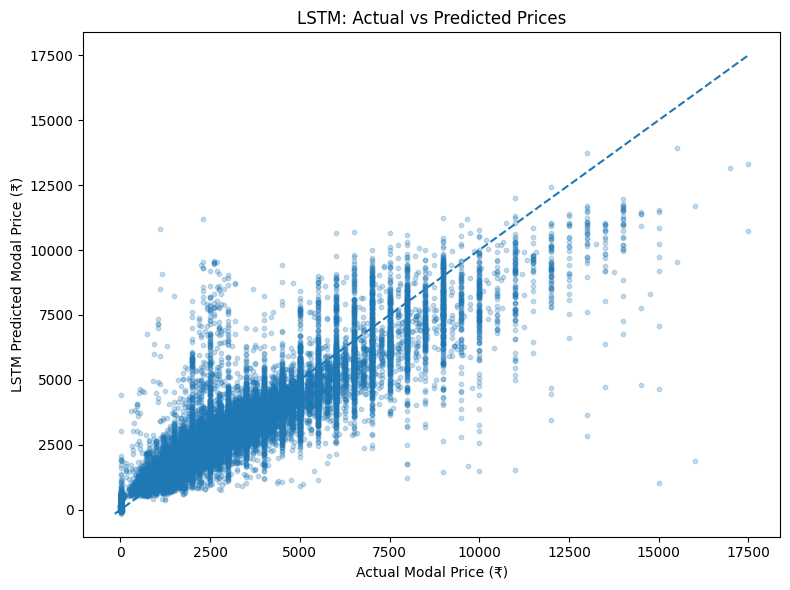

In [ ]:
# ACTUAL VS PREDICTED PRICE

plt.figure(figsize=(8, 6))

plt.scatter(
    y_actual,
    y_pred,
    alpha=0.25,
    s=10
)

min_price = min(y_actual.min(), y_pred.min())
max_price = max(y_actual.max(), y_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.xlabel("Actual Modal Price (₹)")
plt.ylabel("LSTM Predicted Modal Price (₹)")
plt.title("LSTM: Actual vs Predicted Prices")
plt.tight_layout()
plt.show()

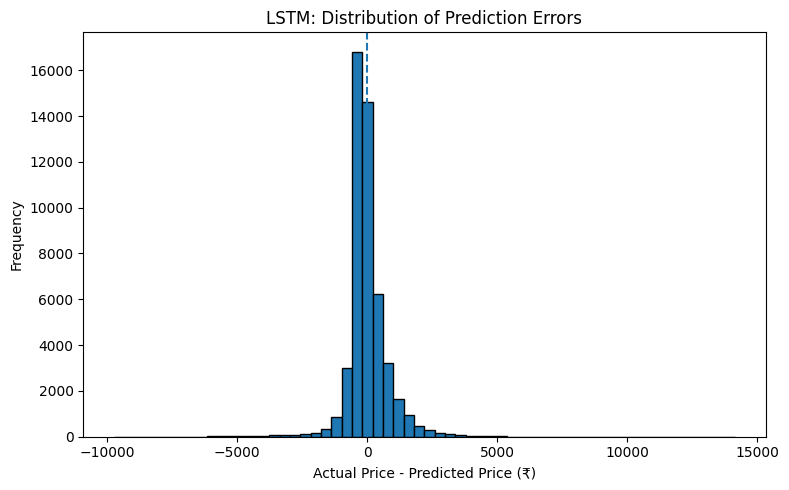

In [ ]:

#ERROR DISTRIBUTION

errors = y_actual - y_pred

plt.figure(figsize=(8, 5))

plt.hist(
    errors,
    bins=60,
    edgecolor="black"
)

plt.axvline(
    0,
    linestyle="--"
)

plt.xlabel("Actual Price - Predicted Price (₹)")
plt.ylabel("Frequency")
plt.title("LSTM: Distribution of Prediction Errors")
plt.tight_layout()
plt.show()

# Feature Importance

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error

rng = np.random.default_rng(42)
N_REPEATS = 5
N_SAMPLES = min(5000, len(y_val))

sample_idx = rng.choice(len(y_val), N_SAMPLES, replace=False)

Xn = X_num_val[sample_idx].copy()
Xc = X_cat_val[sample_idx].copy()
yv = np.asarray(y_val).reshape(-1)[sample_idx]

original_pred = lstm_model.predict(
    [Xn, Xc], batch_size=256, verbose=0
).reshape(-1)

original_mae = mean_absolute_error(yv, original_pred)

results = []

for j, feature in enumerate(numeric_features):
    increases = []

    for _ in range(N_REPEATS):
        Xn_perm = Xn.copy()
        order = rng.permutation(N_SAMPLES)

        Xn_perm[:, :, j] = Xn[order, :, j]

        pred = lstm_model.predict(
            [Xn_perm, Xc], batch_size=256, verbose=0
        ).reshape(-1)

        increases.append(
            mean_absolute_error(yv, pred) - original_mae
        )

    results.append({
        "Feature": feature,
        "Type": "Numerical",
        "MAE_Increase": np.mean(increases),
        "Repeat_SD": np.std(increases, ddof=1)
    })

for j, feature in enumerate(categorical_features):
    increases = []

    for _ in range(N_REPEATS):
        Xc_perm = Xc.copy()
        order = rng.permutation(N_SAMPLES)

        Xc_perm[:, :, j] = Xc[order, :, j]

        pred = lstm_model.predict(
            [Xn, Xc_perm], batch_size=256, verbose=0
        ).reshape(-1)

        increases.append(
            mean_absolute_error(yv, pred) - original_mae
        )

    results.append({
        "Feature": feature,
        "Type": "Categorical",
        "MAE_Increase": np.mean(increases),
        "Repeat_SD": np.std(increases, ddof=1)
    })

lstm_feature_importance = (
    pd.DataFrame(results)
    .sort_values("MAE_Increase", ascending=False)
    .reset_index(drop=True)
)

lstm_feature_importance.insert(
    0, "Rank", np.arange(1, len(lstm_feature_importance) + 1)
)

print("Model analysed: trained LSTM only")
print("Original LSTM validation MAE (scaled):",
      round(original_mae, 5))
print("Validation sequences sampled:", N_SAMPLES)
print("Features analysed:", len(lstm_feature_importance))

display(lstm_feature_importance.round(5))

Model analysed: trained LSTM only
Original LSTM validation MAE (scaled): 0.15694
Validation sequences sampled: 5000
Features analysed: 23


,Rank,Feature,Type,MAE_Increase,Repeat_SD
0,1,Modal Price,Numerical,0.40729,0.00309
1,2,Commodity,Categorical,0.07643,0.00402
2,3,Arrival Quantity,Numerical,0.01974,0.00084
3,4,Market,Categorical,0.01118,0.00051
4,5,District,Categorical,0.00273,0.00041
5,6,Crop_Duration_Days,Numerical,0.00271,0.00004
6,7,Typical_Sowing_Season,Categorical,0.00112,0.00060
7,8,Log_Days_Since_Previous_Observation,Numerical,0.00085,0.00017
8,9,Clay_percent_0_30,Numerical,0.00064,0.00021
9,10,Relative_Humidity_Percent,Numerical,0.00051,0.00021


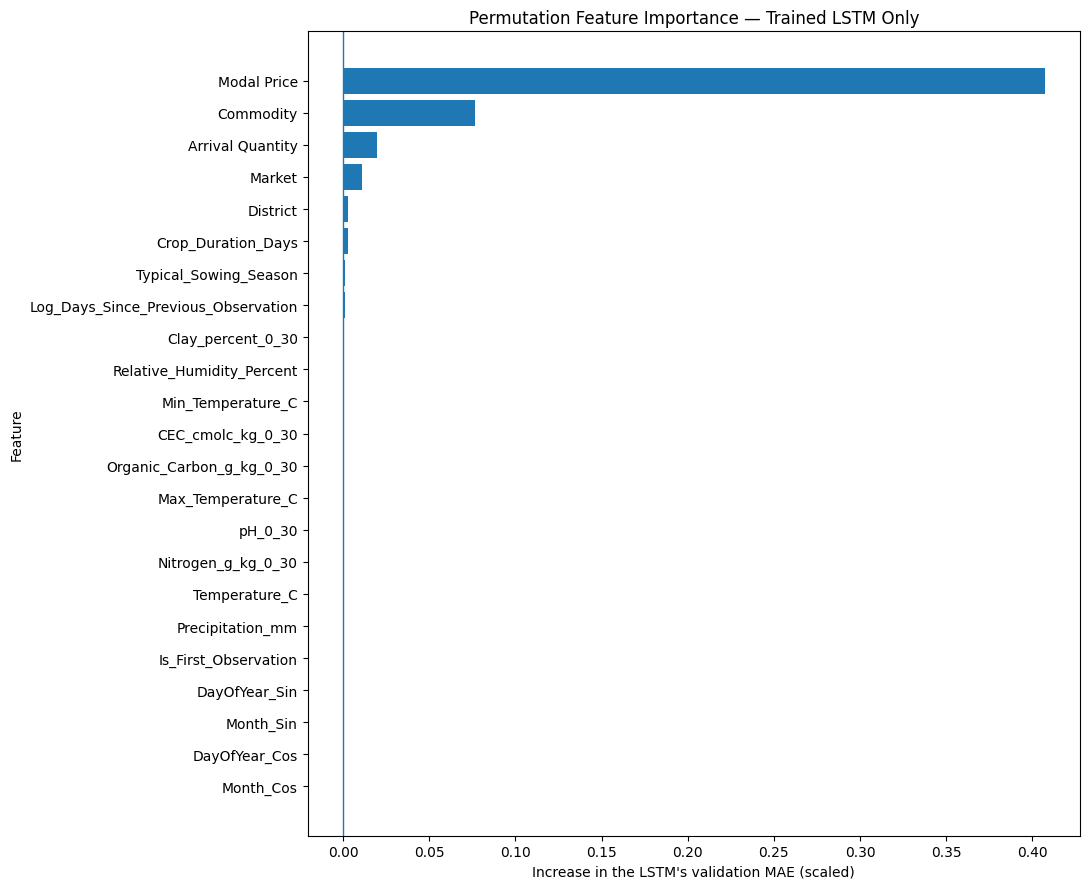

In [ ]:
plot_df = lstm_feature_importance.sort_values(
    "MAE_Increase", ascending=True
)

plt.figure(figsize=(11, 9))
plt.barh(plot_df["Feature"], plot_df["MAE_Increase"])
plt.axvline(0, linewidth=1)
plt.xlabel("Increase in the LSTM's validation MAE (scaled)")
plt.ylabel("Feature")
plt.title("Permutation Feature Importance — Trained LSTM Only")
plt.tight_layout()
plt.show()

# Permutation Analysis

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error

rng = np.random.default_rng(42)
N_REPEATS = 5
N_SAMPLES = min(5000, len(y_val))

sample_idx = rng.choice(
    len(y_val), size=N_SAMPLES, replace=False
)

Xn = X_num_val[sample_idx].copy()
Xc = X_cat_val[sample_idx].copy()
yv = np.asarray(y_val).ravel()[sample_idx]

original_pred = lstm_model.predict(
    [Xn, Xc], batch_size=256, verbose=0
).ravel()

original_mae = mean_absolute_error(yv, original_pred)

results = []

for j, name in enumerate(numeric_features):
    permuted_maes = []

    for _ in range(N_REPEATS):
        Xn_perm = Xn.copy()
        order = rng.permutation(N_SAMPLES)

        Xn_perm[:, :, j] = Xn[order, :, j]

        pred = lstm_model.predict(
            [Xn_perm, Xc], batch_size=256, verbose=0
        ).ravel()

        permuted_maes.append(mean_absolute_error(yv, pred))

    mean_perm_mae = np.mean(permuted_maes)

    results.append({
        "Feature": name,
        "Type": "Numerical",
        "MAE_Increase": mean_perm_mae - original_mae,
        "Repeat_SD": np.std(permuted_maes, ddof=1)
    })

for j, name in enumerate(categorical_features):
    permuted_maes = []

    for _ in range(N_REPEATS):
        Xc_perm = Xc.copy()
        order = rng.permutation(N_SAMPLES)

        Xc_perm[:, :, j] = Xc[order, :, j]

        pred = lstm_model.predict(
            [Xn, Xc_perm], batch_size=256, verbose=0
        ).ravel()

        permuted_maes.append(mean_absolute_error(yv, pred))

    mean_perm_mae = np.mean(permuted_maes)

    results.append({
        "Feature": name,
        "Type": "Categorical",
        "MAE_Increase": mean_perm_mae - original_mae,
        "Repeat_SD": np.std(permuted_maes, ddof=1)
    })

permutation_importance = (
    pd.DataFrame(results)
    .sort_values("MAE_Increase", ascending=False)
    .reset_index(drop=True)
)

permutation_importance.insert(
    0, "Rank", np.arange(1, len(permutation_importance) + 1)
)

print(f"LSTM original validation MAE (scaled): {original_mae:.5f}")
print(f"Validation sequences sampled: {N_SAMPLES}")
print(f"Features analysed: {len(permutation_importance)}")

display(permutation_importance.round(5))

LSTM original validation MAE (scaled): 0.15694
Validation sequences sampled: 5000
Features analysed: 23


,Rank,Feature,Type,MAE_Increase,Repeat_SD
0,1,Modal Price,Numerical,0.40729,0.00309
1,2,Commodity,Categorical,0.07643,0.00402
2,3,Arrival Quantity,Numerical,0.01974,0.00084
3,4,Market,Categorical,0.01118,0.00051
4,5,District,Categorical,0.00273,0.00041
5,6,Crop_Duration_Days,Numerical,0.00271,0.00004
6,7,Typical_Sowing_Season,Categorical,0.00112,0.00060
7,8,Log_Days_Since_Previous_Observation,Numerical,0.00085,0.00017
8,9,Clay_percent_0_30,Numerical,0.00064,0.00021
9,10,Relative_Humidity_Percent,Numerical,0.00051,0.00021


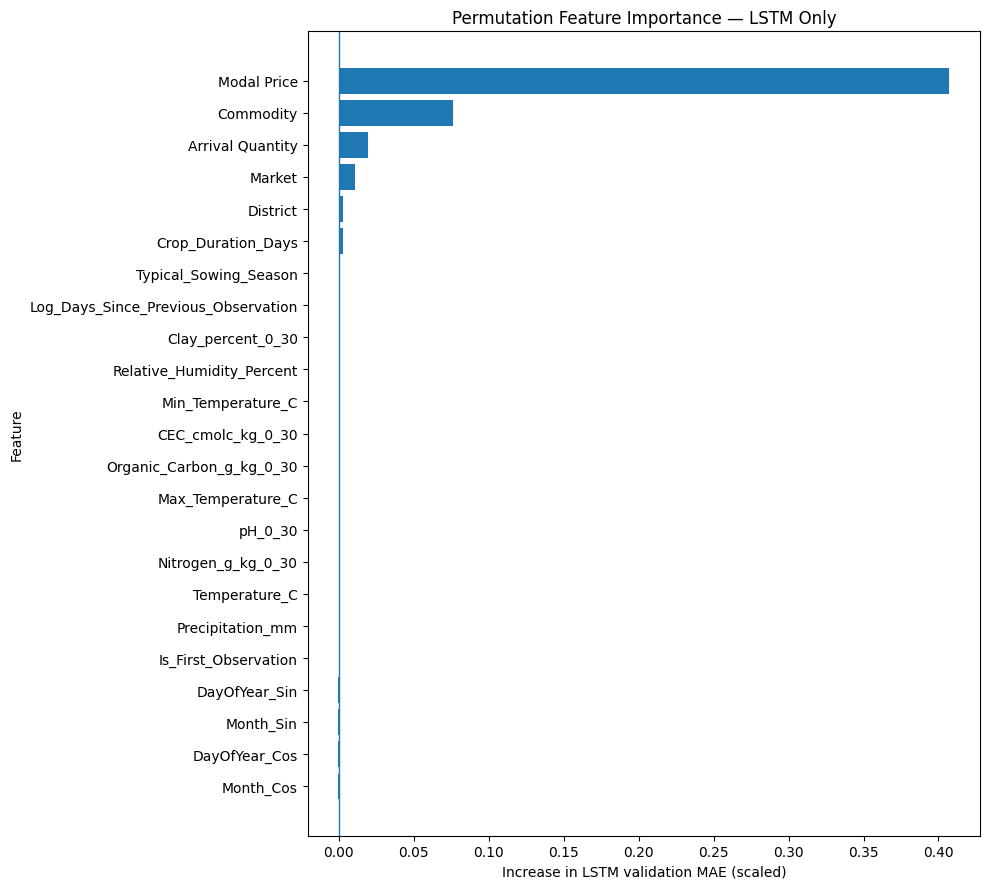

In [ ]:

plot_df = permutation_importance.sort_values(
    "MAE_Increase", ascending=True
)

plt.figure(figsize=(10, 9))
plt.barh(plot_df["Feature"], plot_df["MAE_Increase"])
plt.axvline(0, linewidth=1)
plt.xlabel("Increase in LSTM validation MAE (scaled)")
plt.ylabel("Feature")
plt.title("Permutation Feature Importance — LSTM Only")
plt.tight_layout()
plt.show()

In [ ]:
# SAVE
import os
import json
import shutil
import joblib
import platform
import numpy as np
import tensorflow as tf
import sklearn

from datetime import datetime
from google.colab import drive

drive.mount("/content/drive", force_remount=False)

SAVE_DIR = (
    "/content/drive/MyDrive/"
    "Crop_Market_LSTM_Deployment"
)

os.makedirs(SAVE_DIR, exist_ok=True)

required_objects = [
    "lstm_model",
    "x_scaler",
    "y_scaler",
    "category_maps",
    "category_vocab_sizes",
    "numeric_features",
    "categorical_features",
    "LOOKBACK"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise NameError(
        "Required objects are missing: "
        + ", ".join(missing_objects)
        + ". Run the relevant training/preprocessing cells first."
    )

MODEL_PATH = os.path.join(
    SAVE_DIR,
    "crop_market_modal_price_lstm.keras"
)

lstm_model.save(MODEL_PATH)

print("Saved trained LSTM model:")
print(MODEL_PATH)

preprocessing_artifacts = {
    "x_scaler": x_scaler,
    "y_scaler": y_scaler,
    "category_maps": category_maps,
    "category_vocab_sizes": category_vocab_sizes,
    "numeric_features": list(numeric_features),
    "categorical_features": list(categorical_features),
    "lookback": int(LOOKBACK),
    "target_col": "Modal Price",
    "series_keys": ["Commodity", "Market"],
    "unknown_category_id": 0
}

PREPROCESSOR_PATH = os.path.join(
    SAVE_DIR,
    "preprocessing_artifacts.pkl"
)

joblib.dump(
    preprocessing_artifacts,
    PREPROCESSOR_PATH,
    compress=3
)

print("\nSaved preprocessing artifacts:")
print(PREPROCESSOR_PATH)

deployment_spec = {
    "project": "Crop and Market Modal Price Forecasting",
    "model_type": "TensorFlow/Keras LSTM",
    "target": "Modal Price",
    "target_unit": "Verify against source Price Unit; expected Rs./Quintal",
    "lookback_observations": int(LOOKBACK),
    "forecast_horizon": "One next available observation per Commodity-Market series",
    "series_keys": ["Commodity", "Market"],
    "numeric_features": list(numeric_features),
    "categorical_features": list(categorical_features),
    "numeric_preprocessing": (
        "Use the saved x_scaler, fitted on training rows only, "
        "with numeric_features in the exact saved order."
    ),
    "target_preprocessing": (
        "Model output is scaled. Use the saved y_scaler.inverse_transform "
        "to convert predictions back to the original price scale."
    ),
    "categorical_preprocessing": (
        "Use saved category_maps. Map unseen categories to ID 0. "
        "Do not refit mappings during inference."
    ),
    "sequence_preprocessing": [
        "Sort observations by Commodity, Market, and Date.",
        "Build sequences from the previous LOOKBACK observations.",
        "Keep numerical and categorical sequence order aligned.",
        "Reproduce the training notebook's engineered date and observation-gap features.",
        "Do not use the target observation's actual Modal Price as an input."
    ],
    "engineered_features": {
        "Days_Since_Previous_Observation": (
            "Date difference from the previous observation within each "
            "Commodity-Market series; first observation uses 0."
        ),
        "Log_Days_Since_Previous_Observation": (
            "log1p(Days_Since_Previous_Observation)"
        ),
        "Is_First_Observation": (
            "1 for the first observation in a series, otherwise 0."
        ),
        "DayOfYear_Sin": "Use the same annual cyclical formula as training.",
        "DayOfYear_Cos": "Use the same annual cyclical formula as training."
    },
    "saved_at": datetime.now().isoformat(timespec="seconds")
}

SPEC_PATH = os.path.join(
    SAVE_DIR,
    "deployment_spec.json"
)

with open(SPEC_PATH, "w", encoding="utf-8") as f:
    json.dump(deployment_spec, f, indent=4, ensure_ascii=False)

print("\nSaved deployment specification:")
print(SPEC_PATH)

environment_info = {
    "python_version": platform.python_version(),
    "tensorflow_version": tf.__version__,
    "numpy_version": np.__version__,
    "scikit_learn_version": sklearn.__version__,
    "joblib_version": joblib.__version__
}

ENV_PATH = os.path.join(
    SAVE_DIR,
    "environment_versions.json"
)

with open(ENV_PATH, "w", encoding="utf-8") as f:
    json.dump(environment_info, f, indent=4)

print("\nSaved software versions:")
print(ENV_PATH)

CHECKPOINT_PATH = "/content/best_lstm_model.keras"

if os.path.exists(CHECKPOINT_PATH):
    BEST_PATH = os.path.join(
        SAVE_DIR,
        "best_validation_checkpoint.keras"
    )

    shutil.copy2(CHECKPOINT_PATH, BEST_PATH)

    print("\nSaved best validation checkpoint:")
    print(BEST_PATH)
else:
    print(
        "\nNo separate best checkpoint found. "
        "The current lstm_model was saved above."
    )

print("\n" + "=" * 55)
print("DEPLOYMENT ARTIFACTS SAVED")
print("=" * 55)

for filename in sorted(os.listdir(SAVE_DIR)):
    full_path = os.path.join(SAVE_DIR, filename)

    if os.path.isfile(full_path):
        size_mb = os.path.getsize(full_path) / (1024 ** 2)
        print(f"{filename:<45} {size_mb:>8.2f} MB")

print("\nDeployment folder:")
print(SAVE_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saved trained LSTM model:
/content/drive/MyDrive/Crop_Market_LSTM_Deployment/crop_market_modal_price_lstm.keras

Saved preprocessing artifacts:
/content/drive/MyDrive/Crop_Market_LSTM_Deployment/preprocessing_artifacts.pkl

Saved deployment specification:
/content/drive/MyDrive/Crop_Market_LSTM_Deployment/deployment_spec.json

Saved software versions:
/content/drive/MyDrive/Crop_Market_LSTM_Deployment/environment_versions.json

Saved best validation checkpoint:
/content/drive/MyDrive/Crop_Market_LSTM_Deployment/best_validation_checkpoint.keras

DEPLOYMENT ARTIFACTS SAVED
best_validation_checkpoint.keras                  0.42 MB
crop_market_modal_price_lstm.keras                0.42 MB
deployment_spec.json                              0.00 MB
environment_versions.json                         0.00 MB
preprocessing_artifacts.pkl                       0.00 MB

De